**Importing in the URL**

In [1]:
from bs4 import BeautifulSoup
import requests

#url = 'https://en.wikipedia.org/wiki/List_of_largest_companies_in_the_United_States_by_revenue'
#url = f'https://www.cbssports.com/college-basketball/expert-picks/20250215/'

def process_url(url):
    page = requests.get(url)
    
    soup = BeautifulSoup(page.text, 'html.parser')
    
    #print(soup)
    return soup

**Extracting Team IDs from all the teams before results are announced**

In [2]:
def ids_before_results(soup):
    logos = soup.find_all("div", class_="TeamLogo TeamLogo--small")
    
    team_ids = [logo.find("img")["data-lazy"][-9:-4] for logo in logos]
    
    #print(team_ids)
    return team_ids

**Extracting Team IDs and Predicitions from the teams predicted to win by the EXPERTS**

In [3]:
def ids_expert_picks(soup):
    spread_divs = soup.find_all("div", class_="expert-spread")
    
    predicted_team_ids = [logo.find("img")["data-lazy"][-9:-4] for logo in spread_divs]
    
    # print(predicted_team_ids)
    # print()
    return predicted_team_ids

def expert_predictions(soup):
    spread_divs = soup.find_all("div", class_="expert-spread")
    predictions = [div.get_text(strip=True).split(maxsplit=1) for div in spread_divs]
    
    # print(predictions)
    return predictions

**Extracting all the team names**

In [4]:
def extract_names(soup):
    sports_teams = soup.find_all("span", attrs={"class": "team"})
    
    team_names = [team.get_text(strip=True) for team in sports_teams]
    
    # print(team_names)
    
    return team_names

**Extracting Game odds before the game**

In [5]:
def sportsbook_predicitions(soup):
    game_odds = soup.find_all("div", class_ = "game-odds")
    predictions = [div.get_text(strip=True) for div in game_odds]

    odds_lst = []
    for i in range(1, len(predictions)):
        if i%2 != 0:
            odds_lst.append(predictions[i])
    
    return odds_lst

**Extracting scores all the Team**

In [6]:
def extract_scores(soup):
    teams_score = soup.find_all("span", attrs={"class": "score"})
    
    teams_scores_strip = [score.get_text(strip=True) for score in teams_score]
    
    # print(teams_scores_strip)
    
    return teams_scores_strip

**Kind of Irrelevent Cell but it just matches teams with their scores**

In [7]:
def sample_match_teams_score(names, scores):
    count = 1
    for name, score in zip(names, scores):
        # print(count, ". ", name, "-", score)
        count += 1

**Putting all the data together**

In [8]:
def final_match_teams_score(names, scores, ids, predictions, predicted_team_ids, odds_lst):
    games = [(names[i], names[i+1], scores[i], scores[i+1], ids[i], ids[i+1]) for i in range(0, len(team_names), 2)]
    
    matched_games = [(games[i], predictions[i], predicted_team_ids[i], odds_lst[i]) for i in range(len(predictions))]
    
    # for game, outcome_name, outcome_id in matched_games:
    #     print(f"[{game[4]}] {game[0]} {game[2]} vs [{game[5]}] {game[1]} {game[3]} - Outcome: [{outcome_id}] {outcome_name[0]}\n")

    return matched_games

**See the correctness of the expert predicitions**

In [9]:
def predicition_results (matched_games):
    def find_most_similar(a, b, c):
        if a == c:
            return a
        if b == c:
            return b
    
    correct = 0
    wrong = 0
    
    for game, x, outcome_id, y in matched_games:
        predicted_winner = find_most_similar(game[4], game[5], outcome_id)
     
        if game[2] > game[3]:
            actual_winner = game[4]
        else:
            actual_winner = game[5]
        
        if predicted_winner == actual_winner:
            correct += 1
        else:
            wrong += 1
            
    #print(f"Correct: {correct}\n Wrong: {wrong}")
    return [correct, wrong]

**See the correctness of the sportsbook predicitions** 

In [10]:
def sportbook_predictions(matched_games):
    correct = 0
    wrong = 0
    
    for game, x, y, odds in matched_games:
        if "-" in odds:
            predicted_winner = game[5]
        else:
            predicted_winner = game[4]

        if game[2] > game[3]:
            actual_winner = game[4]
        else:
            actual_winner = game[5]

        if predicted_winner == actual_winner:
            correct += 1
        else:
            wrong += 1
            
    # print(f"Correct: {correct}\n Wrong: {wrong}")
    return [correct, wrong]

**See the correctness when sportsbook and predictions pick the same winner** 

In [11]:
def sportsbook_expert_prediction(matched_games):
    correct = 0
    wrong = 0
    
    #sportsbooks
    for game, x, y, odds in matched_games:
        if "-" in odds:
            predicted_winner_sportsbook = game[5]
        else:
            predicted_winner_sportsbook = game[4]

    #experts
    def find_most_similar(a, b, c):
            if a == c:
                return a
            if b == c:
                return b
        
    correct = 0
    wrong = 0
        
    for game, x, outcome_id, y in matched_games:
        predicted_winner_experts = find_most_similar(game[4], game[5], outcome_id)

    #actual outcome 
    if game[2] > game[3]:
            actual_winner = game[4]
    else:
        actual_winner = game[5]

    if predicted_winner_sportsbook == predicted_winner_experts:
        if predicted_winner_sportsbook == actual_winner:
            correct += 1
        else:
            wrong += 1

    # print(f"Correct: {correct}\n Wrong: {wrong}")
    return [correct, wrong]

**Display the data for the month**

In [12]:
correct_list = []
wrong_list = []
ratio_expert = []
ratio_sportbook = []
ratio_sportbooks_expert = []
dates = []

for i in range(20250201, 20250217+1):
    url = f'https://www.cbssports.com/college-basketball/expert-picks/{i}/'
    soup = process_url(url)
    
    team_ids = ids_before_results(soup)
    predicted_team_ids = ids_expert_picks(soup)
    predictions = expert_predictions(soup)
    team_names = extract_names(soup)
    team_scores = extract_scores(soup)
    odds_lst = sportsbook_predicitions(soup)
    sample_match_teams_score(team_names, team_scores)
    games = final_match_teams_score(team_names, team_scores, team_ids, predictions, predicted_team_ids, odds_lst)
    
    predicted_results = predicition_results(games)
    try:
        ratio_expert.append(predicted_results[0]/(predicted_results[0]+predicted_results[1]))
    except ZeroDivisionError:
        ratio_expert.append(0)
        
    sportsbook_prediction_results = sportbook_predictions(games)
    try:
        ratio_sportbook.append(sportsbook_prediction_results[0]/(sportsbook_prediction_results[0]+sportsbook_prediction_results[1]))
    except ZeroDivisionError:
        ratio_sportbook.append(0)

    sportsbook_experts_prediction_results = sportsbook_expert_prediction(games)
    try:
        ratio_sportbooks_expert.append(sportsbook_experts_prediction_results[0]/(sportsbook_experts_prediction_results[0]+sportsbook_experts_prediction_results[1]))
    except ZeroDivisionError:
        ratio_sportbooks_expert.append(0)
    
    dates.append(int(i))

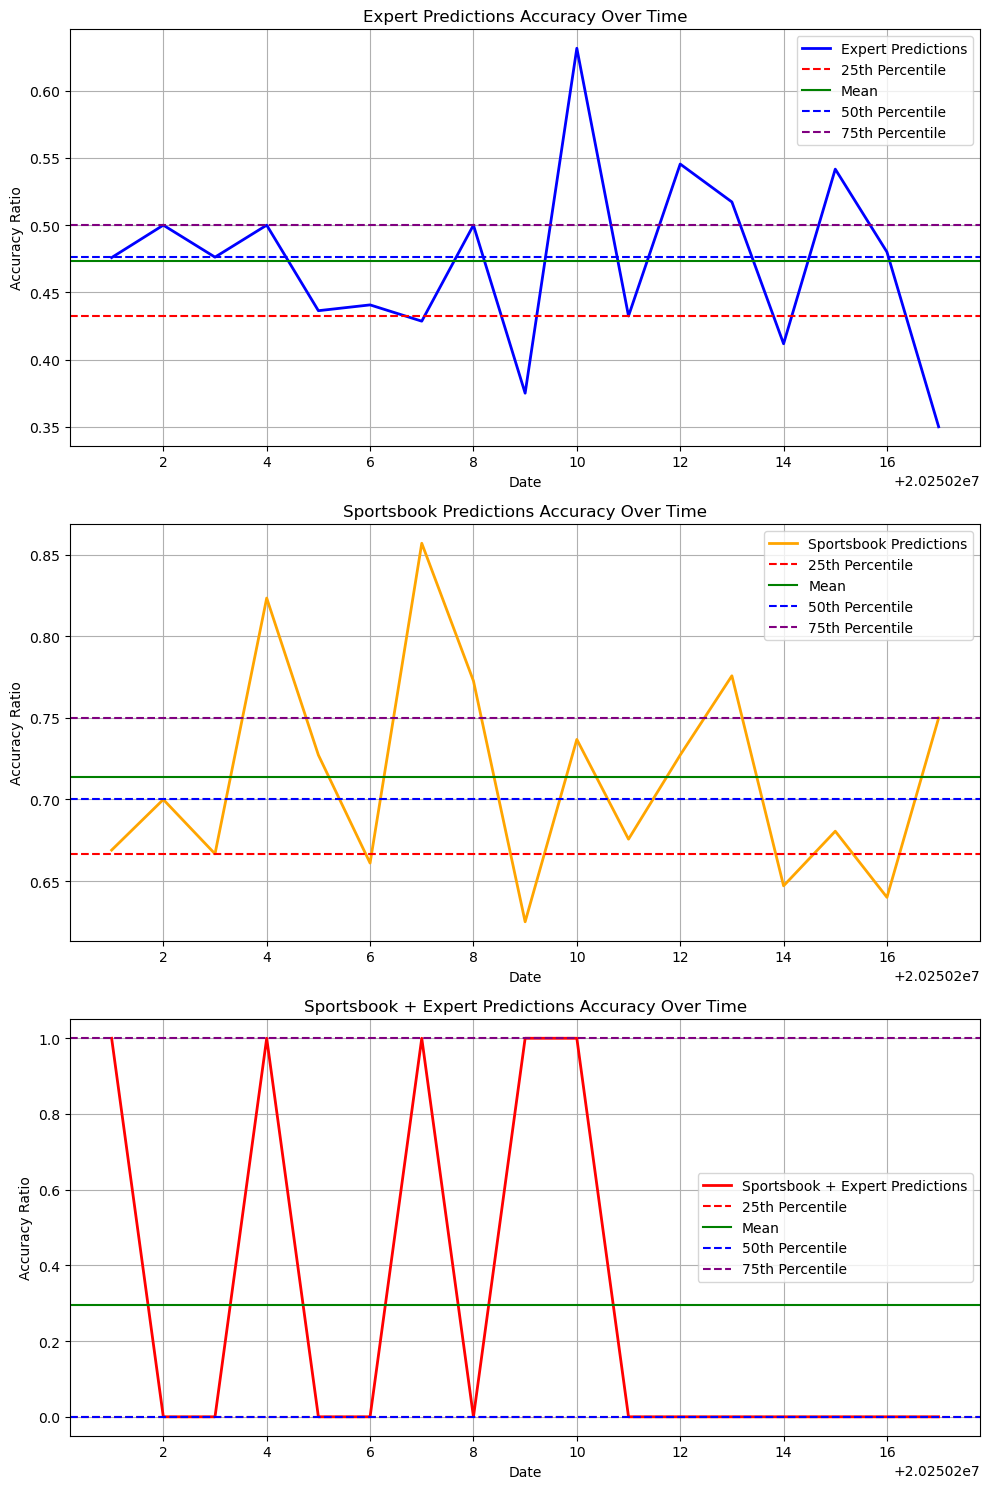

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate percentiles and mean for ratio_expert
q25_expert = np.percentile(ratio_expert, 25)
mean_expert = np.mean(ratio_expert)
q50_expert = np.percentile(ratio_expert, 50)
q75_expert = np.percentile(ratio_expert, 75)

# Calculate percentiles and mean for ratio_sportbook
q25_sportbook = np.percentile(ratio_sportbook, 25)
mean_sportbook = np.mean(ratio_sportbook)
q50_sportbook = np.percentile(ratio_sportbook, 50)
q75_sportbook = np.percentile(ratio_sportbook, 75)

# Calculate percentiles and mean for ratio_sportbook_experts
q25_sportbook_experts = np.percentile(ratio_sportbooks_expert, 25)
mean_sportbook_experts = np.mean(ratio_sportbooks_expert)
q50_sportbook_experts = np.percentile(ratio_sportbooks_expert, 50)
q75_sportbook_experts = np.percentile(ratio_sportbooks_expert, 75)

# Create a figure with three subplots
fig, axs = plt.subplots(3, 1, figsize=(10, 15))

# Plot ratio_expert
axs[0].plot(dates, ratio_expert, label="Expert Predictions", color='b', linestyle='-', linewidth=2)
axs[0].axhline(q25_expert, color='r', linestyle='--', label='25th Percentile')
axs[0].axhline(mean_expert, color='g', linestyle='-', label='Mean')
axs[0].axhline(q50_expert, color='b', linestyle='--', label='50th Percentile')
axs[0].axhline(q75_expert, color='purple', linestyle='--', label='75th Percentile')
axs[0].set_xlabel("Date")
axs[0].set_ylabel("Accuracy Ratio")
axs[0].set_title("Expert Predictions Accuracy Over Time")
axs[0].grid(True)
axs[0].legend()

# Plot ratio_sportbook
axs[1].plot(dates, ratio_sportbook, label="Sportsbook Predictions", color='orange', linestyle='-', linewidth=2)
axs[1].axhline(q25_sportbook, color='r', linestyle='--', label='25th Percentile')
axs[1].axhline(mean_sportbook, color='g', linestyle='-', label='Mean')
axs[1].axhline(q50_sportbook, color='b', linestyle='--', label='50th Percentile')
axs[1].axhline(q75_sportbook, color='purple', linestyle='--', label='75th Percentile')
axs[1].set_xlabel("Date")
axs[1].set_ylabel("Accuracy Ratio")
axs[1].set_title("Sportsbook Predictions Accuracy Over Time")
axs[1].grid(True)
axs[1].legend()

# Plot ratio_sportbooks_expert on the same graph
axs[2].plot(dates, ratio_sportbooks_expert, label="Sportsbook + Expert Predictions", color='red', linestyle='-', linewidth=2)
axs[2].axhline(q25_sportbook_experts, color='r', linestyle='--', label='25th Percentile')
axs[2].axhline(mean_sportbook_experts, color='g', linestyle='-', label='Mean')
axs[2].axhline(q50_sportbook_experts, color='b', linestyle='--', label='50th Percentile')
axs[2].axhline(q75_sportbook_experts, color='purple', linestyle='--', label='75th Percentile')
axs[2].set_xlabel("Date")
axs[2].set_ylabel("Accuracy Ratio")
axs[2].set_title("Sportsbook + Expert Predictions Accuracy Over Time")
axs[2].grid(True)
axs[2].legend()

# Adjust layout and show plot
plt.tight_layout()
plt.show()
